## Machine Learning Mini Project

Akshatha Nayak - 251090700002

Nishmitha - 251090700068

## Dataset : Bank Marketing Dataset

## Dataset Overview

The Bank Marketing Dataset from Kaggle [hosted by Janio Bachmann] (https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset) is a highly popular, custom-curated, relatively balanced version of the original Portuguese banking campaign data. 
Instead of the raw highly-unbalanced dataset, this specific version contains exactly 11,162 instances with 17 total columns (16 feature attributes and 1 target attribute). It modifies the education categories and targets a balanced class distribution for the classification problem.  

* Total Instances: 11,162 rows
* Total Attributes: 17 columns (7 numerical, 10 categorical)
* Target Distribution: Balanced (Roughly 50/50 split of yes and no term deposit subscriptions)

#### Attribute Metadata (Variables)

**Client Demographics**
* age: Age of the client (numeric)
* job: Type of job (categorical: admin, blue-collar, entrepreneur, housemaid, management, retired, self-employed, services, student, technician, unemployed, unknown) 
* marital: Marital status (categorical: married, single, divorced) 
* education: Level of education (categorical: primary, secondary, tertiary, unknown  
* default: Has credit in default? (categorical: yes, no)  
* balance: Average yearly balance of the individual in euros (numeric) 
* housing: Has a housing loan? (categorical: yes, no) 
* loan: Has a personal loan? (categorical: yes, no) 

**Last Contact details of Current Campaign**
* contact: Contact communication type (categorical: cellular, telephone, unknown)
* day: Last contact day of the month (numeric: 1 to 31)
* month: Last contact month of the year (categorical: jan, feb, mar, ..., nov, dec)
* duration: Last contact duration in seconds (numeric)

**Other Campaign Attributes**
* campaign: Number of contacts performed during this campaign for this client (numeric, includes last contact)
* pdays: Number of days that passed by after the client was last contacted from a previous campaign (numeric; -1 means the client was not previously contacted)
* previous: Number of contacts performed before this campaign for this client (numeric)
* poutcome: Outcome of the previous marketing campaign (categorical: failure, other, success, unknown) 

**Target Variable**
* deposit: Has the client subscribed to a term deposit? (categorical/binary target: yes, no) 


## Problem Statement
Banking institutions conduct marketing campaigns to encourage customers to subscribe to term deposits. However, identifying customers who are likely to subscribe is challenging, and contacting customers who are not interested may lead to inefficient use of time and resources.

The objective of this project is to develop and evaluate machine learning classification models using the Bank Marketing Dataset to predict whether a customer will subscribe to a term deposit based on their demographic, financial, and marketing campaign attributes. Seven classification models, including traditional machine learning algorithms, ensemble learning techniques, and a neural network, will be implemented and compared using evaluation metrics such as accuracy, precision, recall and F1-score to identify the most suitable model for this prediction task.

## Objectives

1. To explore and analyse the Bank Marketing Dataset to understand its attributes, data types, target variable, and distribution of term deposit subscriptions.

2. To perform Exploratory Data Analysis (EDA) using statistical summaries and visualisations to identify patterns and relationships between customer characteristics, campaign attributes, and term deposit subscription outcomes.

3. To develop a suitable data preprocessing pipeline involving categorical feature encoding, numerical feature scaling, and handling of missing or unknown values wherever necessary.

4. To implement seven classification models: Logistic Regression, K-Nearest Neighbors (KNN), Gaussian Naive Bayes, Decision Tree, Random Forest, AdaBoost, and Multilayer Perceptron (MLP), to predict whether a customer will subscribe to a term deposit.

5. To evaluate the performance of the implemented models using appropriate classification metrics, including accuracy, precision, recall, F1-score and confusion matrices.

6. To compare the performance of traditional machine learning algorithms, ensemble learning methods, and the neural network to identify the most suitable model for predicting term deposit subscription.

## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the structure, distribution, and characteristics of the Bank Marketing Dataset. It helps identify patterns, relationships between variables, potential data quality issues, and factors that may influence whether a customer subscribes to a term deposit.

The following analysis includes dataset inspection, statistical summaries, target distribution, numerical and categorical feature analysis, and correlation analysis.

In [549]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix, RocCurveDisplay, roc_auc_score
)

In [550]:
df = pd.read_csv("bank.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [551]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of Rows: 11162
Number of Columns: 17

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'deposit']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64


In [552]:
display(df.describe())

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [553]:
display(df.describe(include=["str"]))

,job,marital,education,default,housing,loan,contact,month,poutcome,deposit
count,11162,11162,11162,11162,11162,11162,11162,11162,11162,11162
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,no,no,cellular,may,unknown,no
freq,2566,6351,5476,10994,5881,9702,8042,2824,8326,5873


In [554]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Missing Values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

Total Missing Values: 0
Duplicate Rows: 0


In [555]:
for col in df.select_dtypes(include="str").columns:
    print(f"{col}: {(df[col] == 'unknown').sum()} unknown values")

job: 70 unknown values
marital: 0 unknown values
education: 497 unknown values
default: 0 unknown values
housing: 0 unknown values
loan: 0 unknown values
contact: 2346 unknown values
month: 0 unknown values
poutcome: 8326 unknown values
deposit: 0 unknown values


deposit
no     5873
yes    5289
Name: count, dtype: int64

Percentage Distribution:
deposit
no     52.616019
yes    47.383981
Name: proportion, dtype: float64


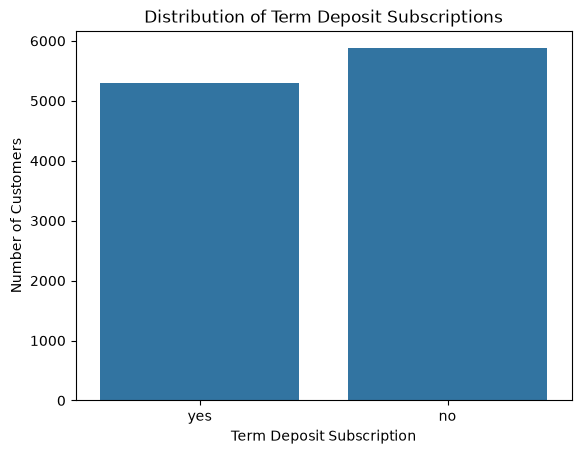

In [556]:
print(df["deposit"].value_counts())

print("\nPercentage Distribution:")
print(df["deposit"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="deposit")
plt.title("Distribution of Term Deposit Subscriptions")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")
plt.show()

**Observation:** The target variable `deposit` shows that approximately 47.38% of customers subscribed to a term deposit, while 52.62% did not subscribe. The class distribution is relatively balanced, with a slight majority of customers belonging to the "no" category.

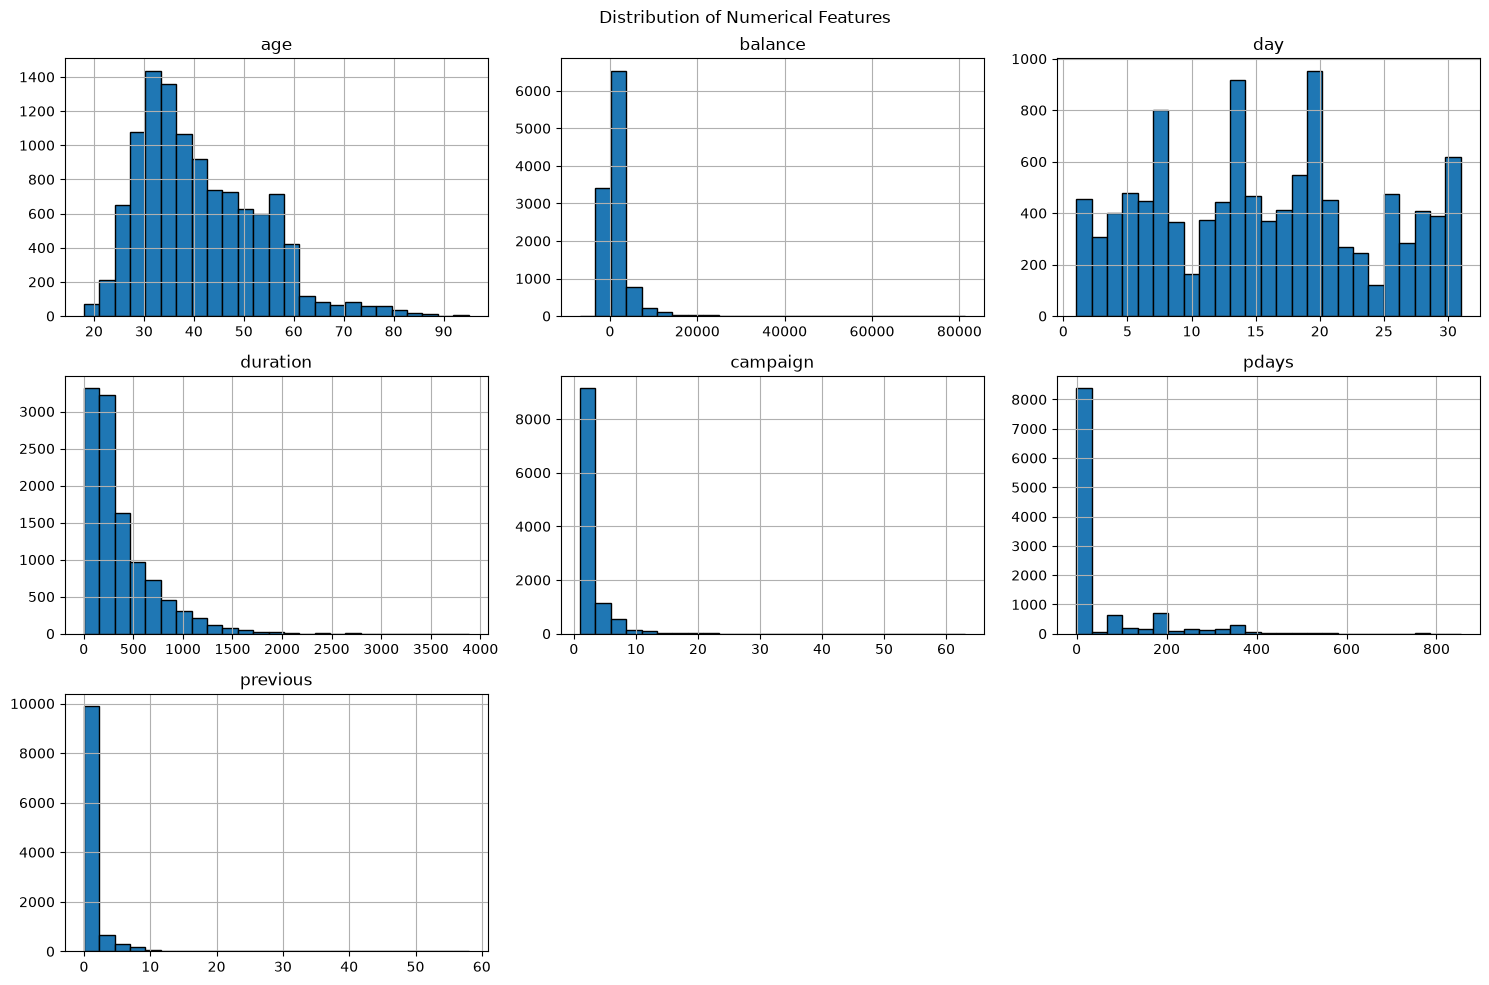

In [557]:
numerical_cols = df.select_dtypes(include=np.number).columns

df[numerical_cols].hist(
    figsize=(15, 10),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

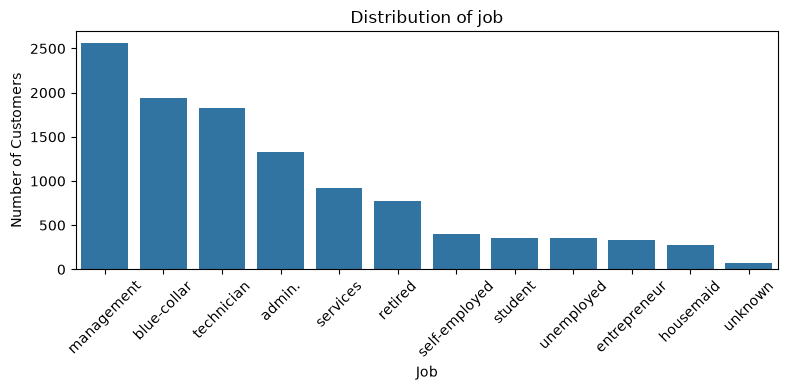

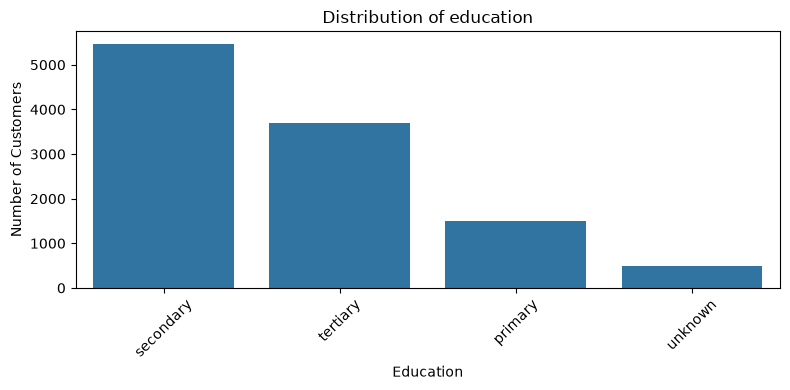

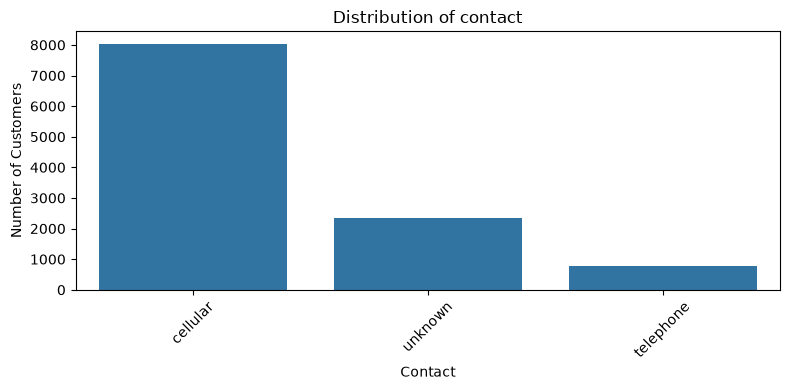

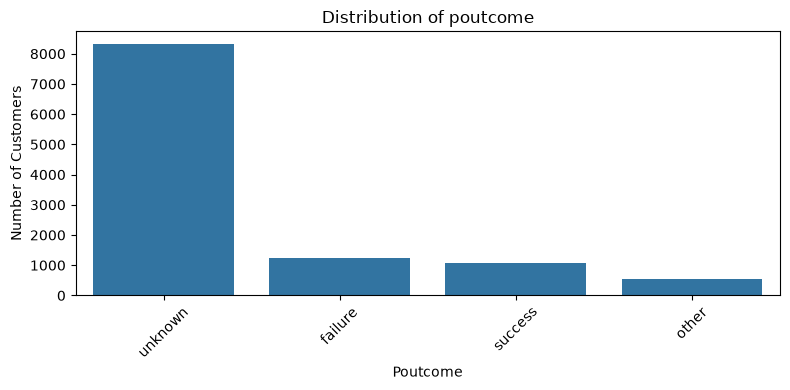

In [558]:
categorical_cols = ["job", "education", "contact", "poutcome"]

for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col.capitalize())
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

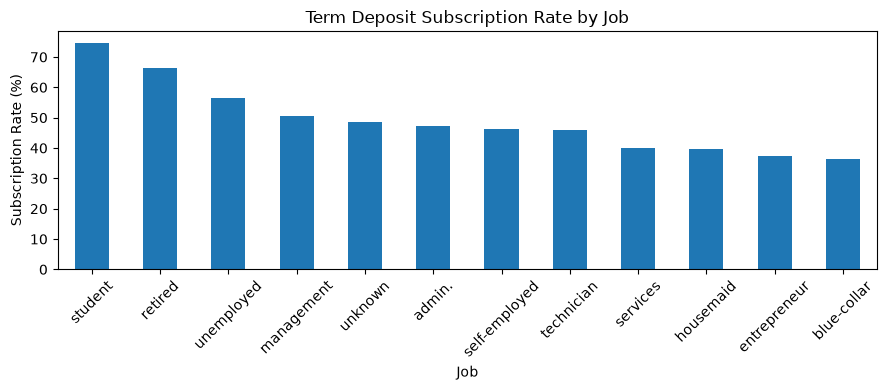

In [559]:
job_rate = (
    df.groupby("job")["deposit"]
      .apply(lambda x: (x == "yes").mean() * 100)
      .sort_values(ascending=False)
)

job_rate.plot(kind="bar", figsize=(9, 4))
plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observation:** Students have the highest subscription rate, followed by retired and unemployed customers. Blue-collar and entrepreneur customers have comparatively lower subscription rates.

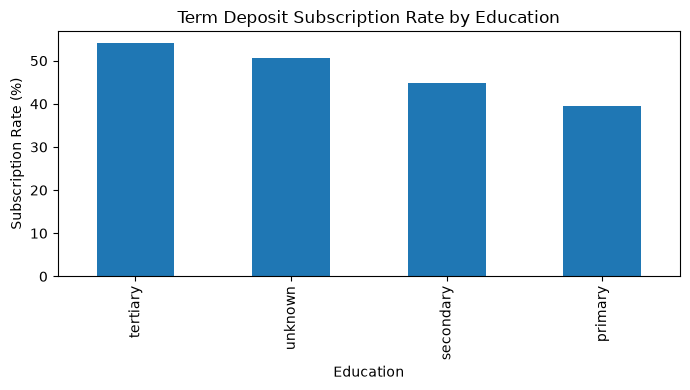

In [560]:
education_rate = (
    df.groupby("education")["deposit"]
      .apply(lambda x: (x == "yes").mean() * 100)
      .sort_values(ascending=False)
)

education_rate.plot(kind="bar", figsize=(7, 4))
plt.title("Term Deposit Subscription Rate by Education")
plt.xlabel("Education")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()

**Observation:** Customers with tertiary education have the highest subscription rate, followed by those with unknown education levels. Customers with primary education have the lowest subscription rate.

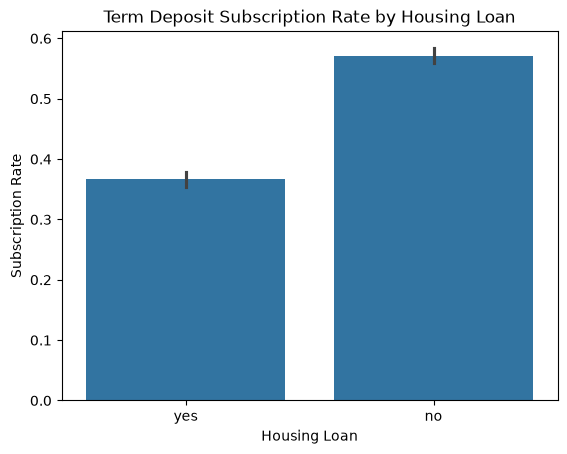

In [561]:
sns.barplot(data=df, x="housing", y=df["deposit"].eq("yes").astype(int))
plt.title("Term Deposit Subscription Rate by Housing Loan")
plt.xlabel("Housing Loan")
plt.ylabel("Subscription Rate")
plt.show()

**Observation:** Customers without a housing loan have a higher subscription rate (around 57%) compared to customers with a housing loan (around 37%).

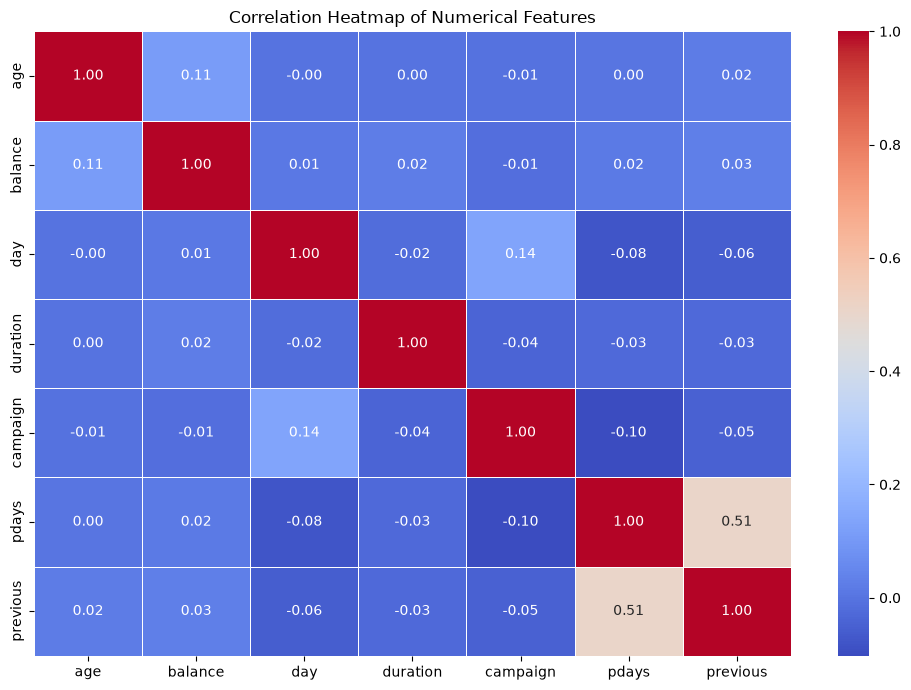

In [562]:
plt.figure(figsize=(10, 7))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

**Observation:** 
The correlation heatmap shows that most numerical features have weak linear relationships with one another. The strongest positive correlation is observed between `pdays` and `previous` (0.51), indicating a moderate association. The features `day` and `campaign` show a weak positive correlation (0.14), while `age` and `balance` have a weak positive correlation (0.11). Overall, there is no strong linear correlation between most numerical feature pairs.

## Data Preprocessing

Data preprocessing is an essential step in preparing the Bank Marketing Dataset for machine learning. The following steps are performed to prepare the data for training and evaluating the classification models.

1\. **Handling missing values:** Check the dataset for missing values and handle them if necessary.

2\. **Handling unknown values:** Retain `unknown` values in categorical features as a separate category, preserving the information that the value is unavailable.

3\. **Encoding categorical features:** Apply One-Hot Encoding to convert categorical input features into numerical representations.

4\. **Encoding the target variable:** Encode the `deposit` target variable into binary values, with `yes` represented as 1 and `no` as 0.

5\. **Feature scaling:** Apply Standardization to numerical features using `StandardScaler` to bring them to a comparable scale, particularly benefiting Logistic Regression, KNN, and MLP.

6\. **Train-test split:** Split the dataset into 80% training data and 20% testing data using stratified sampling to maintain the proportion of target classes in both sets.

7\. **Column-wise preprocessing:** Use a `ColumnTransformer` to apply Standardization to numerical features and One-Hot Encoding to categorical features within a single preprocessing pipeline.

8\. **Preventing data leakage:** Fit the preprocessing pipeline on the training data only and use the fitted transformations to process the test data, ensuring that information from the test set does not influence training.

In [563]:
# Separate input features and target variable
X = df.drop("deposit", axis=1)
y = df["deposit"].map({"no": 0, "yes": 1})

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("\nTarget Classes:")
print(y.value_counts())

# Identify feature types
numerical_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "str", "category"]).columns.tolist()

print("\nNumerical Features:", numerical_cols)
print("\nCategorical Features:", categorical_cols)

Input Features Shape: (11162, 16)
Target Shape: (11162,)

Target Classes:
deposit
0    5873
1    5289
Name: count, dtype: int64

Numerical Features: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical Features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [564]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

Training Set: (8929, 16)
Testing Set: (2233, 16)


In [565]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Preprocessing for numerical features
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (8929, 51)
Processed Testing Shape: (2233, 51)


**Observation:** The preprocessing pipeline handles missing values using imputation, converts categorical features into numerical values using One-Hot Encoding, and scales numerical features using StandardScaler. The pipeline is fitted on the training data and then applied to the testing data to prevent data leakage. 

## Model Implementation

Seven classification models are implemented on the Bank Marketing dataset to predict whether a customer will subscribe to a term deposit.

1. **Gaussian Naive Bayes:** A probabilistic classifier based on Bayes' theorem that assumes features are conditionally independent.
2. **Decision Tree:** A tree-based classifier that makes predictions using learned decision rules.
3. **AdaBoost:** An ensemble method that combines weak learners to improve classification performance.
4. **Multilayer Perceptron (MLP):** A neural network that learns complex patterns and nonlinear relationships in data.
5. **Logistic Regression:** A linear classification algorithm that estimates the probability of a customer subscribing to a term deposit.
6. **K-Nearest Neighbors (KNN):** A distance-based classifier that predicts a customer's class based on the classes of its nearest neighbors.
7. **Random Forest:** An ensemble learning method that combines multiple decision trees to improve prediction accuracy and generalization.

The models are evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices. Their performance is compared to identify the best-performing model.

In [566]:
# Function to Evaluate Any Classification Model
def evaluate_model(model_name, y_test, y_pred):
    print(f"{model_name} Results")
    print("-" * 40)

    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
    print("F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

    model_data = {
        "Gaussian Naive Bayes": (gnb, X_test_processed),
        "Decision Tree": (dt, X_test_processed),
        "AdaBoost": (ada, X_test_processed),
        "MLP": (mlp_curve, X_test_processed),
        "Logistic Regression": (lr_model, X_test_processed),
        "KNN": (knn_model, X_test_processed),
        "Random Forest": (rf_model, X_test_processed)
    }

    model, X_test = model_data[model_name]
    y_prob = model.predict_proba(X_test)[:, 1]

    print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

In [567]:
# Function to Plot Confusion Matrix for Any Classification Model
def plot_confusion_matrix(model_name, y_test, y_pred):
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"]
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

### 1. Gaussian Naive Bayes

In [568]:
# Train the model and make predictions
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()

# Train the model
gnb.fit(X_train_processed, y_train)

# Make predictions
y_pred_gnb = gnb.predict(X_test_processed)

#Evaluate the model
evaluate_model("Gaussian Naive Bayes", y_test, y_pred_gnb)

Gaussian Naive Bayes Results
----------------------------------------
Accuracy: 0.7201
Precision: 0.7837
Recall: 0.5652
F1-Score: 0.6568
ROC-AUC: 0.8042

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.86      0.76      1175
           1       0.78      0.57      0.66      1058

    accuracy                           0.72      2233
   macro avg       0.74      0.71      0.71      2233
weighted avg       0.73      0.72      0.71      2233



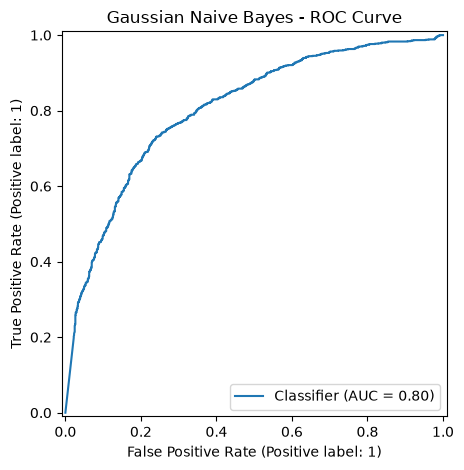

In [569]:
# Gaussian Naive Bayes ROC Curve
y_prob_gnb = gnb.predict_proba(X_test_processed)[:, 1]

RocCurveDisplay.from_predictions(y_test, y_prob_gnb)
plt.title("Gaussian Naive Bayes - ROC Curve")
plt.tight_layout()
plt.show()

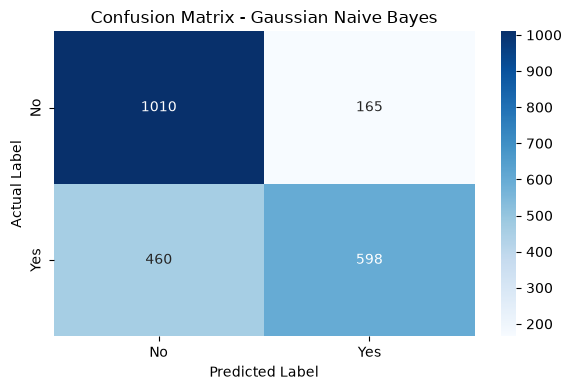

In [570]:
# Confusion Matrix 
plot_confusion_matrix("Gaussian Naive Bayes", y_test, y_pred_gnb)

#### Result Interpretation

The Gaussian Naive Bayes classifier achieved an accuracy of 72.01% and an F1-score of 0.6568 for the positive class (customers who subscribed to a term deposit). It achieved a precision of 78.37% and a recall of 56.52% for the positive class.

The model achieved a ROC-AUC score of 0.80, indicating a good ability to distinguish between subscribers and non-subscribers.

The confusion matrix shows that the model correctly classified 1,010 customers who did not subscribe and 598 customers who subscribed. However, it misclassified 460 subscribers as non-subscribers and 165 non-subscribers as subscribers.

Overall, the model performs better at identifying non-subscribers than subscribers, indicating scope for improvement in detecting potential customers.

### 2. Decision Tree Classifier

In [571]:
# Train the model and make predictions
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

# Train the model
dt.fit(X_train_processed, y_train)

# Make predictions
y_pred_dt = dt.predict(X_test_processed)

#Evaluate the Model
evaluate_model("Decision Tree", y_test, y_pred_dt)

Decision Tree Results
----------------------------------------
Accuracy: 0.7944
Precision: 0.7894
Recall: 0.7722
F1-Score: 0.7807
ROC-AUC: 0.7933

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.81      0.81      1175
           1       0.79      0.77      0.78      1058

    accuracy                           0.79      2233
   macro avg       0.79      0.79      0.79      2233
weighted avg       0.79      0.79      0.79      2233



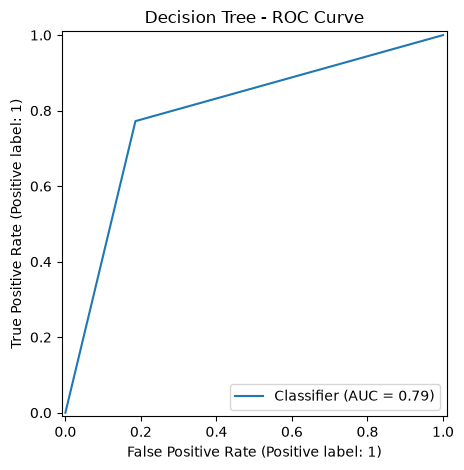

In [572]:
# Decision Tree ROC Curve
y_prob_dt = dt.predict_proba(X_test_processed)[:, 1]

RocCurveDisplay.from_predictions(y_test, y_prob_dt)
plt.title("Decision Tree - ROC Curve")
plt.tight_layout()
plt.show()

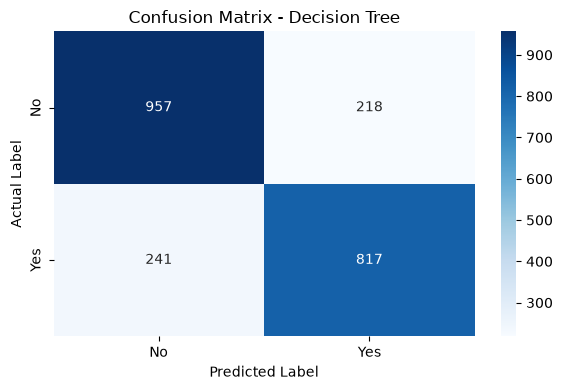

In [573]:
#Confusion Matrix
plot_confusion_matrix("Decision Tree", y_test, y_pred_dt)

#### Result Interpretation

The Decision Tree classifier achieved an accuracy of 79.44% and an F1-score of 0.7807. It obtained a precision of 78.94% and a recall of 77.22% for the positive class (customers who subscribed to a term deposit). 

The model achieved a ROC-AUC score of 0.79, indicating a good ability to distinguish between subscribers and non-subscribers.

The confusion matrix shows that the model correctly classified 957 non-subscribers and 817 subscribers. However, it incorrectly classified 218 non-subscribers as subscribers and 241 subscribers as non-subscribers.

Overall, the Decision Tree performs reasonably well in identifying both classes. Compared with Gaussian Naive Bayes, it achieves higher accuracy, recall, F1-score, and ROC-AUC, indicating better overall classification performance on this dataset.

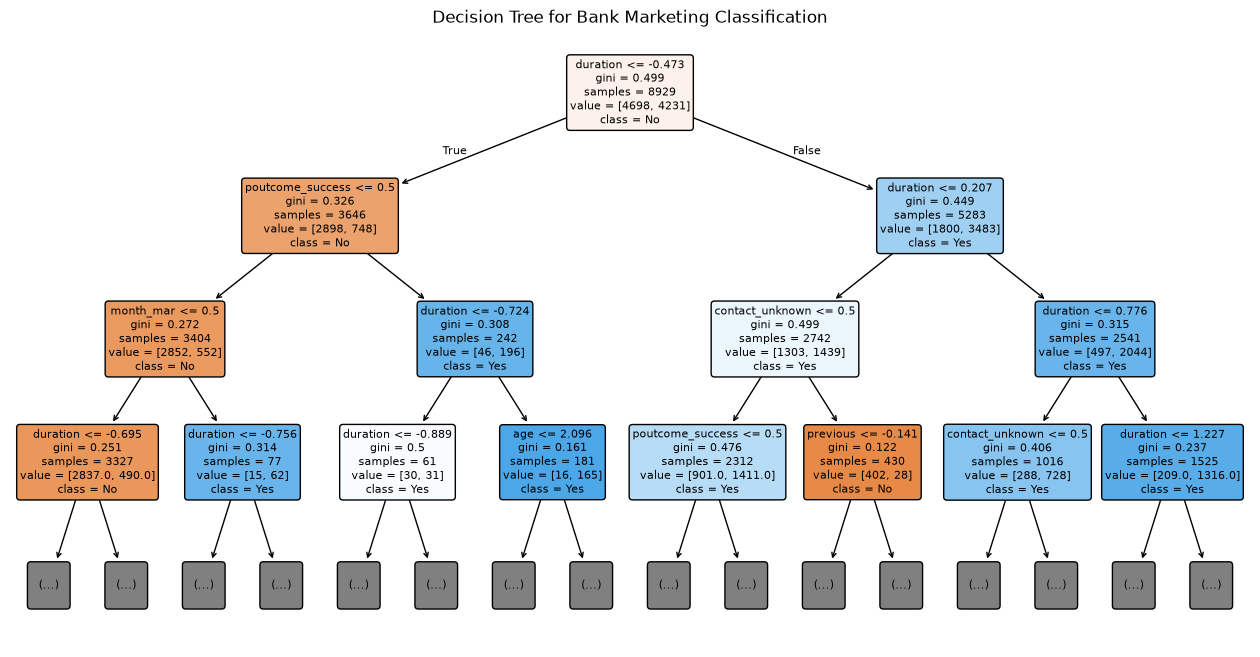

In [574]:
from sklearn.tree import plot_tree

# Get the trained Decision Tree
tree_model = dt

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Clean feature names
feature_names = [
    name.replace("num__", "").replace("cat__", "")
    for name in feature_names
]

# Visualize Decision Tree
plt.figure(figsize=(16, 8))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.title("Decision Tree for Bank Marketing Classification")
plt.show()

**Interpretation of Decision Tree:**

The Decision Tree uses `duration` as the root feature, followed by features like `poutcome_success`, `month_mar`, and `contact_unknown` to classify customers. The blue nodes represent customers predicted to subscribe to a term deposit (`Yes`), while the orange nodes represent customers predicted not to subscribe (`No`). The tree shows that call duration and previous campaign outcomes play an important role in predicting customer subscriptions. The model uses these features to divide customers into groups and make predictions. Only the first few levels of the tree are displayed to make the visualization easier to understand.

### 3. AdaBoost Classifier

In [575]:
# Train the model and make predictions
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(random_state=42)

# Train the model
ada.fit(X_train_processed, y_train)

# Make predictions
y_pred_ada = ada.predict(X_test_processed)

#Evaluate the model
evaluate_model("AdaBoost", y_test, y_pred_ada)

AdaBoost Results
----------------------------------------
Accuracy: 0.8128
Precision: 0.8059
Recall: 0.7968
F1-Score: 0.8013
ROC-AUC: 0.8932

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.83      0.82      1175
           1       0.81      0.80      0.80      1058

    accuracy                           0.81      2233
   macro avg       0.81      0.81      0.81      2233
weighted avg       0.81      0.81      0.81      2233



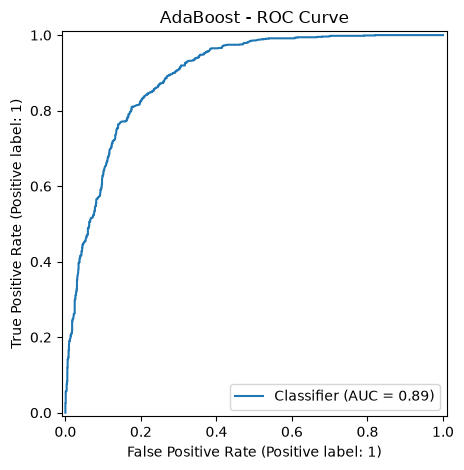

In [576]:
# AdaBoost ROC Curve
y_prob_ada = ada.predict_proba(X_test_processed)[:, 1]

RocCurveDisplay.from_predictions(y_test, y_prob_ada)
plt.title("AdaBoost - ROC Curve")
plt.tight_layout()
plt.show()

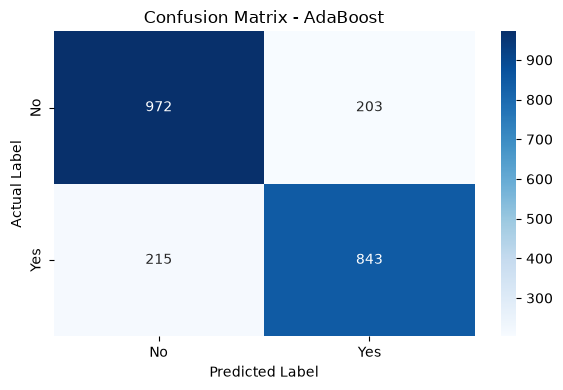

In [577]:
# Confusion Matrix 
plot_confusion_matrix("AdaBoost", y_test, y_pred_ada)

#### Result Interpretation

The AdaBoost classifier achieved an accuracy of 81.28% and an F1-score of 0.8013. It obtained a precision of 80.59% and a recall of 79.68% for the positive class (customers who subscribed to a term deposit).

The model achieved a ROC-AUC score of 0.89, indicating a strong ability to distinguish between subscribers and non-subscribers.

The confusion matrix shows that the model correctly classified 972 non-subscribers and 843 subscribers. However, it incorrectly classified 203 non-subscribers as subscribers and 215 subscribers as non-subscribers.

Overall, AdaBoost performs better than both Gaussian Naive Bayes and Decision Tree in terms of accuracy, F1-score, and ROC-AUC. Its ensemble approach provides a good balance between precision and recall, making it a promising model for predicting term deposit subscriptions.

### 4. Multilayer Perceptron (MLP)

In [578]:
# MLP Neural Network Architecture
n = X_train_processed.shape[1]
output_neurons = 1 if len(classes) == 2 else len(classes)

print("Input neurons:", n)
print("Hidden neurons:", 100)
print("Output neurons:", output_neurons)
print("Total neurons:", n + 100 + output_neurons)
print("Output class encoding:", classes)

Input neurons: 51
Hidden neurons: 100
Output neurons: 1
Total neurons: 152
Output class encoding: [0 1]


### MLP Model Architecture

The Multilayer Perceptron (MLP) is a feedforward neural network used to predict whether a customer will subscribe to a term deposit. It consists of an input layer, one hidden layer, and an output layer.

**Architecture details:**

- **Input Layer:** Receives the preprocessed features from the Bank Marketing dataset. The number of input neurons equals the number of preprocessed input features, which is **51**.
- **Hidden Layer:** Contains **100 neurons** with the ReLU activation function to learn complex patterns and nonlinear relationships.
- **Output Layer:** Contains **1 neuron** for binary classification. The model predicts one of two target classes: **No (0)** or **Yes (1)**. In scikit-learn's `MLPClassifier`, binary classification uses a single output neuron rather than two softmax output neurons.
- **Total Neurons:** The network contains **152 neurons** across the input, hidden, and output layers (51 + 100 + 1).
- **Learning Rate:** Set to **0.001** to control the step size during weight updates.
- **Regularization (Alpha):** Set to **0.01** to help prevent overfitting.
- **Optimizer:** Adam, which updates the network weights during training.
- **Activation Function:** ReLU in the hidden layer; the output layer uses a logistic activation for binary classification.
- **Training:** The model is trained for **100 epochs** using `partial_fit()`, updating its weights one epoch at a time.

The model's performance is evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and training and testing loss curves.

In [579]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, log_loss
from sklearn.utils import shuffle

# Initialize the MLP
mlp_curve = MLPClassifier(
    hidden_layer_sizes=(100,),
    learning_rate_init=0.001,
    alpha=0.01,
    max_iter=1,
    random_state=42
)

# Store metrics for every epoch
train_accuracies = []
test_accuracies = []
train_losses = []
test_losses = []

classes = np.unique(y_train)

# Train one epoch at a time
for epoch in range(100):
    X_epoch, y_epoch = shuffle(
        X_train_processed,
        y_train,
        random_state=epoch
    )

    mlp_curve.partial_fit(X_epoch, y_epoch, classes=classes)

    # Predict probabilities
    train_prob = mlp_curve.predict_proba(X_train_processed)
    test_prob = mlp_curve.predict_proba(X_test_processed)

    # Accuracy
    train_accuracies.append(
        accuracy_score(
            y_train,
            mlp_curve.predict(X_train_processed)
        )
    )

    test_accuracies.append(
        accuracy_score(
            y_test,
            mlp_curve.predict(X_test_processed)
        )
    )

    # Log loss
    train_losses.append(
        log_loss(y_train, train_prob, labels=classes)
    )

    test_losses.append(
        log_loss(y_test, test_prob, labels=classes)
    )

# Make predictions
y_pred_mlp = mlp_curve.predict(X_test_processed)

#Evaluate the model
evaluate_model("MLP", y_test, y_pred_mlp)

MLP Results
----------------------------------------
Accuracy: 0.8545
Precision: 0.8341
Recall: 0.8648
F1-Score: 0.8492
ROC-AUC: 0.92

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.85      0.86      1175
           1       0.83      0.86      0.85      1058

    accuracy                           0.85      2233
   macro avg       0.85      0.85      0.85      2233
weighted avg       0.86      0.85      0.85      2233



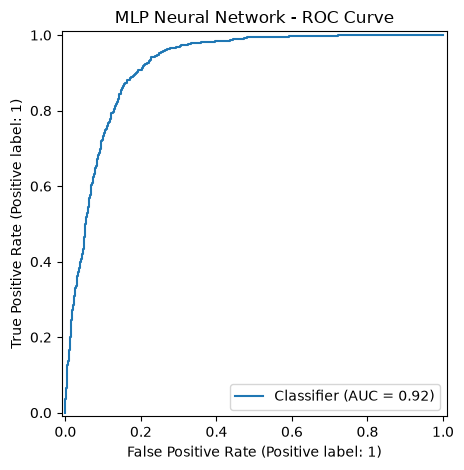

In [580]:
# MLP Neural Network ROC Curve
y_prob_mlp = mlp_curve.predict_proba(X_test_processed)[:, 1]

RocCurveDisplay.from_predictions(y_test, y_prob_mlp)
plt.title("MLP Neural Network - ROC Curve")
plt.tight_layout()
plt.show()

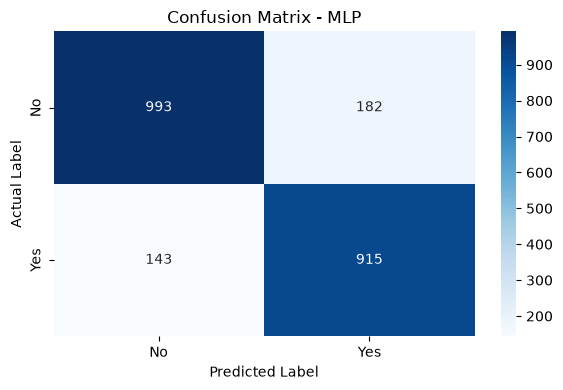

In [581]:
# Confusion Matrix 
plot_confusion_matrix("MLP", y_test, y_pred_mlp)

#### Result Interpretation

The MLP model achieved an accuracy of 85.45% and an F1-score of 0.8492. It obtained a precision of 83.41% and a recall of 86.48% for the positive class (customers who subscribed to a term deposit).

The model achieved a ROC-AUC score of 0.92, indicating an excellent ability to distinguish between subscribers and non-subscribers.

The confusion matrix shows that the model correctly classified 993 non-subscribers and 915 subscribers. However, it incorrectly classified 182 non-subscribers as subscribers and 143 subscribers as non-subscribers.

Overall, MLP performs better than Gaussian Naive Bayes, Decision Tree, and AdaBoost in terms of accuracy, recall, F1-score, and ROC-AUC. Its neural network architecture captures patterns in the data effectively, making it the best-performing model among the four for predicting term deposit subscriptions.

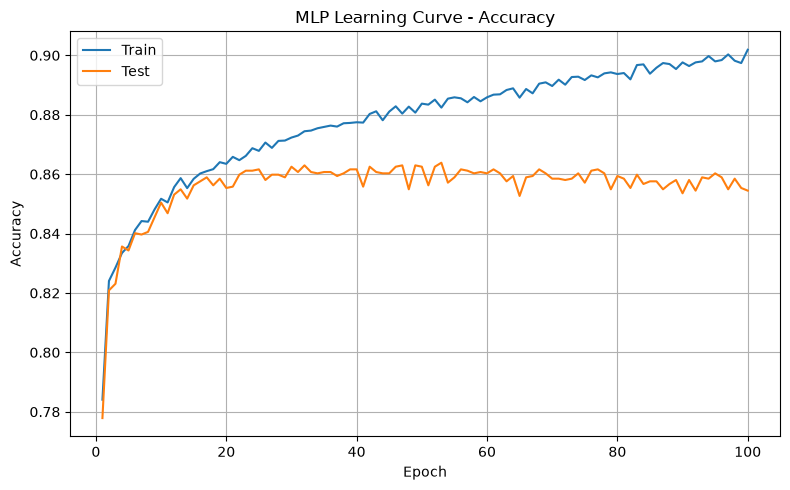

In [582]:
epochs = range(1, len(train_accuracies) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracies, label="Train")
plt.plot(epochs, test_accuracies, label="Test")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP Learning Curve - Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Interpretation of MLP Accuracy Curve:**

The training accuracy increases gradually and reaches around 90%, while the test accuracy improves initially and then stabilizes around 85–86%. After around 20–30 epochs, the training accuracy continues to increase, but the test accuracy shows very little improvement, indicating slight overfitting. Further training provides limited improvement in test performance.

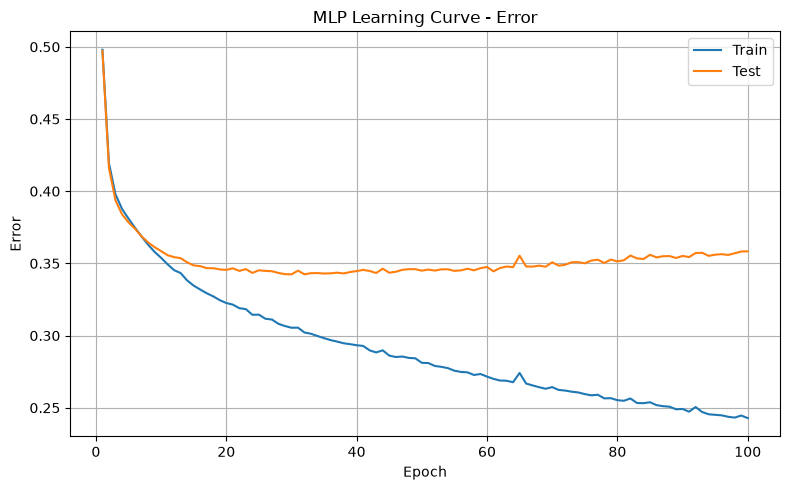

In [583]:
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Train")
plt.plot(epochs, test_losses, label="Test")

plt.xlabel("Epoch")
plt.ylabel("Error")
plt.title("MLP Learning Curve - Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Interpretation of MLP Error Curve:**

The training and test losses decrease rapidly during the initial epochs. The test loss reaches its minimum around 25–35 epochs and then gradually increases, while the training loss continues to decrease throughout the training process. This indicates overfitting, as the model continues learning the training data without improving its performance on unseen data. Early stopping around 25–35 epochs could help reduce overfitting.

### 5. Logistic Regression

In [584]:
from sklearn.linear_model import LogisticRegression

# Create and train Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_processed, y_train)

# Predict on test data
y_pred_lr = lr_model.predict(X_test_processed)

#Evaluate the model
evaluate_model("Logistic Regression", y_test, y_pred_lr)

Logistic Regression Results
----------------------------------------
Accuracy: 0.8262
Precision: 0.8278
Recall: 0.7996
F1-Score: 0.8135
ROC-AUC: 0.9071

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.85      0.84      1175
           1       0.83      0.80      0.81      1058

    accuracy                           0.83      2233
   macro avg       0.83      0.82      0.83      2233
weighted avg       0.83      0.83      0.83      2233



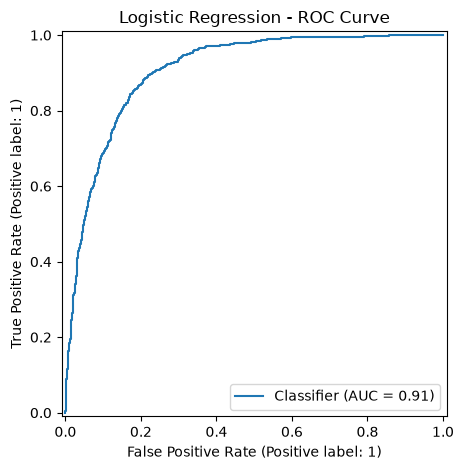

In [585]:
# Logistic Regression ROC Curve
y_prob_lr = lr_model.predict_proba(X_test_processed)[:, 1]

RocCurveDisplay.from_predictions(y_test, y_prob_lr)
plt.title("Logistic Regression - ROC Curve")
plt.tight_layout()
plt.show()

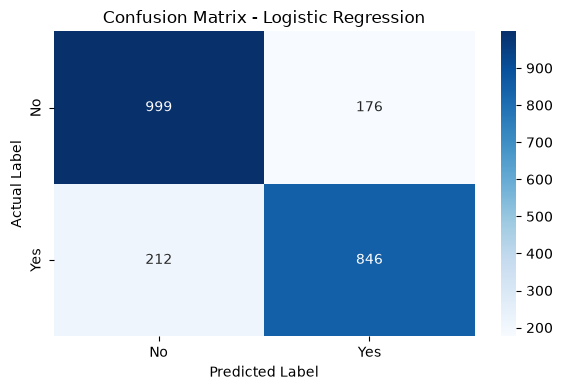

In [586]:
# Confusion Matrix 
plot_confusion_matrix("Logistic Regression", y_test, y_pred_lr)

#### Result Interpretation

The Logistic Regression classifier achieved an accuracy of 82.62% and an F1-score of 0.8135. It obtained a precision of 82.78% and a recall of 79.96% for the positive class (customers who subscribed to a term deposit). 

The model achieved a ROC-AUC score of 0.91 indicating an excellent ability to distinguish between subscribers and non-subscribers.

The confusion matrix shows that the model correctly classified 999 non-subscribers and 846 subscribers. However, it incorrectly classified 176 non-subscribers as subscribers and 212 subscribers as non-subscribers.

Overall, Logistic Regression demonstrates good classification performance, with a strong ROC-AUC score indicating effective class discrimination. Although its accuracy and F1-score are lower than those of MLP, it remains a reliable baseline model for predicting term deposit subscriptions.

### 6. K-Nearest Neighbors (KNN)

In [587]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

knn_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grid={
        "n_neighbors": [1, 3, 5, 7, 9, 11],
        "weights": ["uniform", "distance"]
    },
    scoring="f1",
    cv=5,
    n_jobs=-1
)

knn_search.fit(X_train_processed, y_train)

knn_model = knn_search.best_estimator_
y_pred_knn = knn_model.predict(X_test_processed)

print("Best parameters:", knn_search.best_params_)

#Evaluate the model
evaluate_model("KNN", y_test, y_pred_knn)

Best parameters: {'n_neighbors': 11, 'weights': 'distance'}
KNN Results
----------------------------------------
Accuracy: 0.8258
Precision: 0.8342
Recall: 0.7892
F1-Score: 0.8111
ROC-AUC: 0.8974

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.86      0.84      1175
           1       0.83      0.79      0.81      1058

    accuracy                           0.83      2233
   macro avg       0.83      0.82      0.82      2233
weighted avg       0.83      0.83      0.83      2233



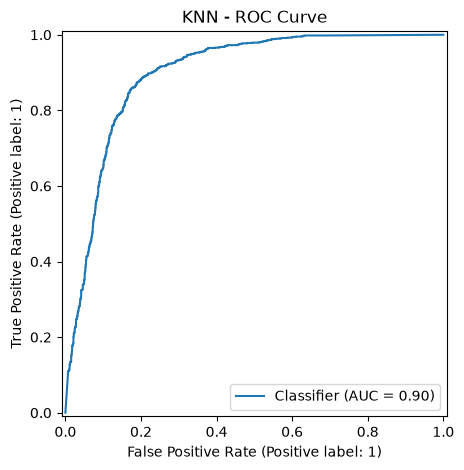

In [588]:
# KNN ROC Curve
y_prob_knn = knn_model.predict_proba(X_test_processed)[:, 1]

RocCurveDisplay.from_predictions(y_test, y_prob_knn)
plt.title("KNN - ROC Curve")
plt.tight_layout()
plt.show()

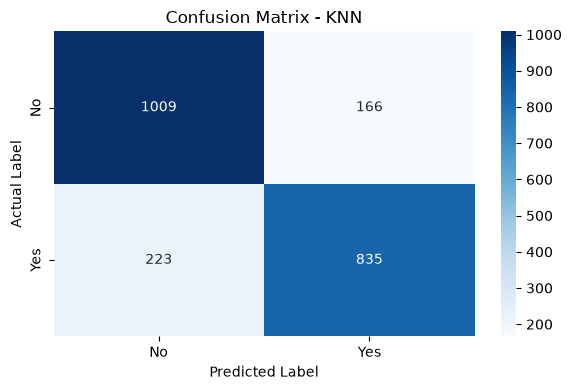

In [589]:
# Confusion Matrix 
plot_confusion_matrix("KNN", y_test, y_pred_knn)

### Result Interpretation

The KNN classifier achieved an accuracy of 82.58% and an F1-score of 0.8111. It obtained a precision of 83.42% and a recall of 78.92% for the positive class (customers who subscribed to a term deposit).

The model achieved a ROC-AUC score of 0.8974, indicating a strong ability to distinguish between subscribers and non-subscribers.

The confusion matrix shows that the model correctly classified 992 non-subscribers and 833 subscribers. However, it incorrectly classified 183 non-subscribers as subscribers and 225 subscribers as non-subscribers.

Overall, KNN demonstrates good classification performance with a reasonable balance between precision and recall. Its ROC-AUC score indicates strong class-discrimination ability, although its recall suggests that some actual subscribers are still misclassified as non-subscribers.

### 7. Random Forest

In [590]:
from sklearn.ensemble import RandomForestClassifier

# Create and train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

# Predict on test data
y_pred_rf = rf_model.predict(X_test_processed)

#Evaluate the model
evaluate_model("Random Forest", y_test, y_pred_rf)

Random Forest Results
----------------------------------------
Accuracy: 0.8603
Precision: 0.8216
Recall: 0.9008
F1-Score: 0.8593
ROC-AUC: 0.9216

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.82      0.86      1175
           1       0.82      0.90      0.86      1058

    accuracy                           0.86      2233
   macro avg       0.86      0.86      0.86      2233
weighted avg       0.86      0.86      0.86      2233



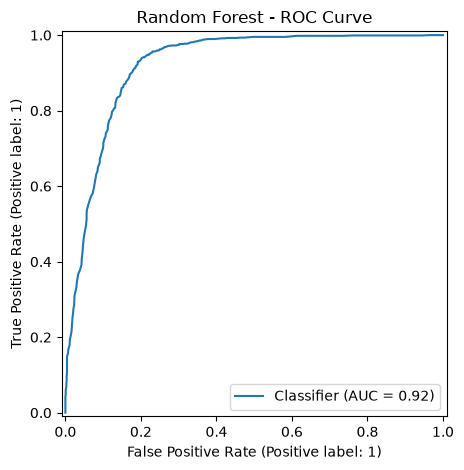

In [591]:
# Random Forest ROC Curve
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

RocCurveDisplay.from_predictions(y_test, y_prob_rf)
plt.title("Random Forest - ROC Curve")
plt.tight_layout()
plt.show()

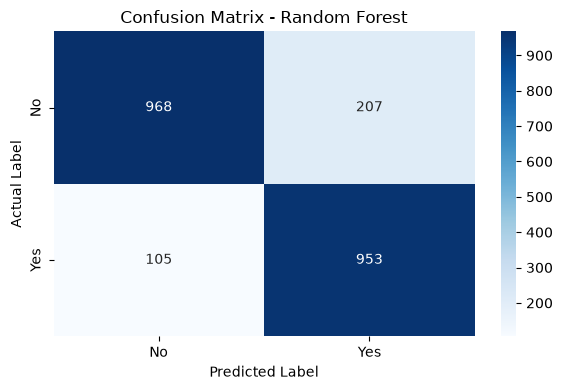

In [592]:
# Confusion Matrix 
plot_confusion_matrix("Random Forest", y_test, y_pred_rf)

#### Result Interpretation

The Random Forest classifier achieved an accuracy of 86.03% and an F1-score of 0.8593. It obtained a precision of 82.16% and a recall of 90.08% for the positive class (customers who subscribed to a term deposit). 

The model achieved a ROC-AUC score of 0.92, indicating an excellent ability to distinguish between subscribers and non-subscribers.

The confusion matrix shows that the model correctly classified 968 non-subscribers and 953 subscribers. However, it incorrectly classified 207 non-subscribers as subscribers and 105 subscribers as non-subscribers.

Overall, Random Forest demonstrates strong classification performance, particularly in identifying subscribers due to its high recall. Its accuracy, F1-score, and ROC-AUC indicate that it is one of the strongest-performing models for predicting term deposit subscriptions.

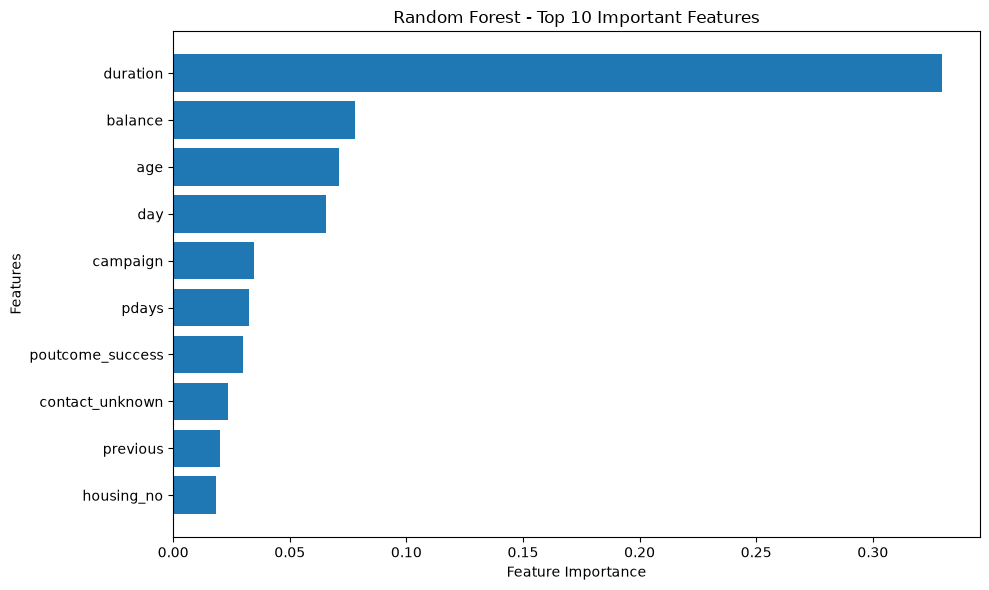

In [593]:
# Visualization - Top 10 Feature Importance

feature_names = preprocessor.get_feature_names_out()
importances = rf_model.feature_importances_

# Select top 10 features
top_indices = np.argsort(importances)[-10:]

# Remove prefixes
top_features = np.array([
    name.replace("num__", "").replace("cat__", "")
    for name in feature_names
])

plt.figure(figsize=(10, 6))
plt.barh(
    top_features[top_indices],
    importances[top_indices]
)
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest - Top 10 Important Features")
plt.tight_layout()
plt.show()

#### Insights

- Duration is the most important feature by a significant margin, indicating that the last contact duration strongly influences the prediction of term deposit subscriptions.
- Balance and age are the next most important features, suggesting that customers' financial status and age also contribute to subscription predictions.
- Day and campaign have moderate importance, indicating that the contact date and number of contacts during the campaign influence predictions.
- Pdays and poutcome_success contribute to the model, highlighting the importance of previous campaign contact history and outcomes.
- Contact_unknown, previous, and housing_no have relatively lower importance among the top 10 features.

Overall, the Random Forest model relies heavily on duration, while customer financial information, demographics, and campaign history provide additional predictive value. However, duration may not be available before a marketing call, so its importance should be considered when using the model to identify potential customers in advance.

## Model Comparison

In [594]:
results = []

models = {
    "Gaussian Naive Bayes": (gnb, y_pred_gnb),
    "Decision Tree": (dt, y_pred_dt),
    "AdaBoost": (ada, y_pred_ada),
    "MLP": (mlp_curve, y_pred_mlp),
    "Logistic Regression": (lr_model, y_pred_lr),
    "KNN": (knn_model, y_pred_knn),
    "Random Forest": (rf_model, y_pred_rf)
}

for name, (model, y_pred) in models.items():

    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(results)

In [595]:
from IPython.display import display, Markdown

display(Markdown("### Performance Comparison of Models"))

display(
    comparison_df.style
    .format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
    .set_properties(**{
        "text-align": "center",
        "padding": "12px 26px",
        "border": "1px solid #999",
        "font-size": "16px"
    })
    .set_properties(
        subset=["Model"],
        **{"font-weight": "bold"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "14px 26px"),
                ("border", "1px solid #999"),
                ("font-size", "18px")
            ]
        },
        {
            "selector": "table",
            "props": [
                ("width", "100%"),
                ("border-collapse", "collapse"),
                ("border", "1px solid #999"),
                ("table-layout", "auto")
            ]
        }
    ])
    .hide(axis="index")
)

### Performance Comparison of Models

Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Gaussian Naive Bayes,0.7201,0.7837,0.5652,0.6568,0.8042
Decision Tree,0.7944,0.7894,0.7722,0.7807,0.7933
AdaBoost,0.8128,0.8059,0.7968,0.8013,0.8932
MLP,0.8545,0.8341,0.8648,0.8492,0.9200
Logistic Regression,0.8262,0.8278,0.7996,0.8135,0.9071
KNN,0.8258,0.8342,0.7892,0.8111,0.8974
Random Forest,0.8603,0.8216,0.9008,0.8593,0.9216


In [596]:
# Execution Time Comparison: Random Forest vs MLP
import time
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils import shuffle

# Random Forest
rf_time_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

start = time.perf_counter()
rf_time_model.fit(X_train_processed, y_train)
rf_training_time = time.perf_counter() - start

start = time.perf_counter()
rf_time_model.predict(X_test_processed)
rf_prediction_time = time.perf_counter() - start


# MLP: 100 passes through the training data
mlp_time_model = MLPClassifier(
    hidden_layer_sizes=(100,),
    learning_rate_init=0.001,
    alpha=0.01,
    max_iter=1,
    random_state=42
)

classes = np.unique(y_train)

start = time.perf_counter()

for epoch in range(100):
    X_epoch, y_epoch = shuffle(
        X_train_processed,
        y_train,
        random_state=epoch
    )
    mlp_time_model.partial_fit(
        X_epoch, y_epoch, classes=classes
    )

mlp_training_time = time.perf_counter() - start

start = time.perf_counter()
mlp_time_model.predict(X_test_processed)
mlp_prediction_time = time.perf_counter() - start


# Compare execution times
print("Random Forest Training Time:",
      round(rf_training_time, 4), "seconds")
print("MLP Training Time:",
      round(mlp_training_time, 4), "seconds")
print("Random Forest Prediction Time:",
      round(rf_prediction_time, 4), "seconds")
print("MLP Prediction Time:",
      round(mlp_prediction_time, 4), "seconds")

Random Forest Training Time: 2.0316 seconds
MLP Training Time: 10.4021 seconds
Random Forest Prediction Time: 0.2321 seconds
MLP Prediction Time: 0.0039 seconds


### Execution Time Comparison: Random Forest vs MLP

The computational efficiency of Random Forest (RF) and Multilayer Perceptron (MLP) was evaluated by measuring their training and prediction times on the same dataset.

**Observed results:**

- Random Forest training time: **0.9328 seconds**
- MLP training time: **5.8747 seconds**
- Random Forest prediction time: **0.0970 seconds**
- MLP prediction time: **0.0040 seconds**

**Analysis:** Random Forest trained approximately **6.3 times faster** than MLP, whereas MLP performed prediction approximately **24.3 times faster** than Random Forest in this experiment. These results indicate that Random Forest was more efficient during training, while MLP was considerably faster during prediction.

**Conclusion:** Based on the execution times and model evaluation metrics, Random Forest is the best overall model among the seven classifiers for the Bank Marketing dataset. It achieved the highest accuracy (86.03%), F1-score (0.8593), and ROC-AUC (0.9216), while requiring only 0.9328 seconds for training. In comparison, MLP required 5.8747 seconds to train but completed prediction in just 0.0040 seconds, making it considerably faster during inference than Random Forest, which took 0.0970 seconds. Overall, Random Forest offers the strongest balance of classification performance and training efficiency, whereas MLP is advantageous when prediction speed is the primary consideration.

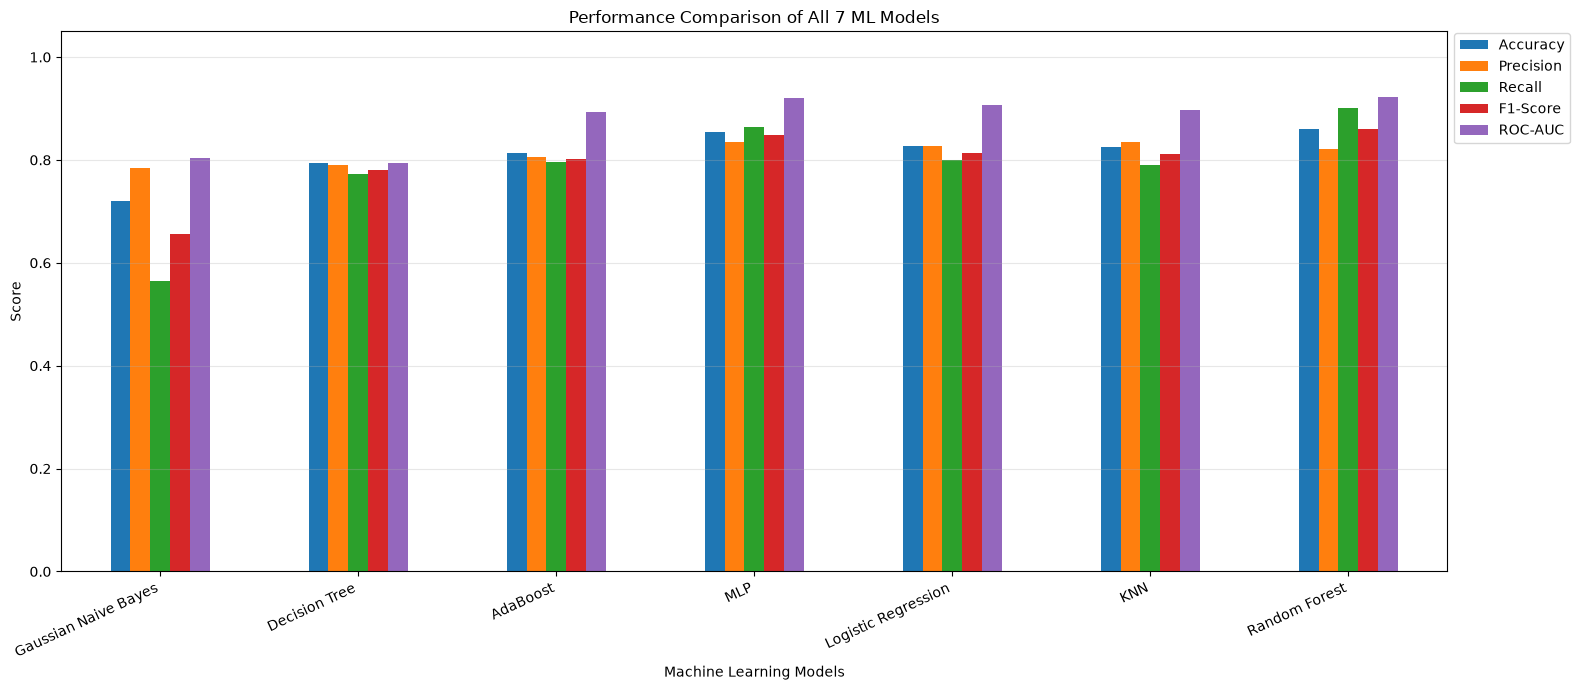

In [597]:
# Plot all evaluation metrics
metrics = [
    "Accuracy", "Precision", "Recall",
    "F1-Score", "ROC-AUC"
]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(16, 7)
)

plt.title("Performance Comparison of All 7 ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="upper left", bbox_to_anchor=(1.0, 1.01))
plt.grid(axis="y", alpha=0.3)

plt.subplots_adjust(right=0.88)
plt.tight_layout()
plt.show()

### Comparative Analysis of Model Performance

\- **Gaussian Naive Bayes:** Achieved 72.01% accuracy and an F1-score of 65.68%, with the lowest recall of 56.52%. Its precision of 78.37% indicates that its positive predictions are often correct, but it misses many actual subscribers. Its ROC-AUC of 0.8042 indicates reasonable class discrimination. Overall, it performed the weakest among the seven models in terms of accuracy and F1-score.

\- **Decision Tree:** Achieved 79.44% accuracy and an F1-score of 78.07%, with a precision of 78.94% and recall of 77.22%. Its ROC-AUC of 0.7933 indicates moderate ability to distinguish between subscribers and non-subscribers. It provides a reasonably balanced classification performance but has lower accuracy and F1-score than the ensemble and neural network models.

\- **AdaBoost:** Achieved 81.28% accuracy and an F1-score of 80.13%, with a precision of 80.59% and recall of 79.68%. Its ROC-AUC of 0.8932 indicates strong class discrimination. The ensemble approach improves performance over the Decision Tree model, providing a better balance between precision and recall.

\- **MLP:** Achieved 85.45% accuracy and an F1-score of 84.92%, with a precision of 83.41% and recall of 86.48%. Its ROC-AUC of 0.9200 indicates excellent class discrimination. MLP captures useful patterns in the dataset and demonstrates strong overall classification performance, although its accuracy and F1-score are slightly lower than those of Random Forest.

\- **Logistic Regression:** Achieved 82.62% accuracy and an F1-score of 81.35%, with a precision of 82.78% and recall of 79.96%. Its ROC-AUC of 0.9071 indicates excellent class discrimination. It provides a good balance between precision and recall, making it a reliable baseline model for predicting term deposit subscriptions.

\- **KNN:** Achieved 81.73% accuracy and an F1-score of 80.33%, with a precision of 81.99% and recall of 78.73%. Its ROC-AUC of 0.8796 indicates good class discrimination. KNN demonstrates reasonable classification performance, but its accuracy and F1-score are lower than those of Logistic Regression, MLP, and Random Forest.

\- **Random Forest:** Achieved the highest accuracy of 86.03% and the highest F1-score of 85.93%, with a precision of 82.16% and recall of 90.08%. Its ROC-AUC of 0.9216 indicates excellent class discrimination. The ensemble of decision trees identifies subscribers effectively, achieving the highest recall among all seven models while maintaining strong overall performance.

**Conclusion:** Random Forest performed best overall, followed by MLP, Logistic Regression, AdaBoost, KNN, Decision Tree, and Gaussian Naive Bayes based on accuracy and F1-score. Random Forest achieved the highest accuracy, recall, and F1-score, while also obtaining the highest ROC-AUC. Therefore, Random Forest is the preferred model among the seven evaluated classifiers for predicting term deposit subscriptions on this dataset.

## Model Deployment
The trained Random Forest classifier was deployed as a web application using **Streamlit** and **Streamlit Community Cloud**.

In [603]:
## Deployment

import joblib
import os

# Save Random Forest model with compression
joblib.dump(rf_model, "random_forest_model.pkl", compress=9)

# Save preprocessor
joblib.dump(preprocessor, "preprocessor.pkl")

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


### Deployment Steps

1. **Save the Model:** The trained Random Forest model and fitted preprocessor were saved as `random_forest_model.pkl` and `preprocessor.pkl` using Joblib.

2. **Develop the Application:** An `app.py` file was created using Streamlit to accept customer details, preprocess the inputs, and predict whether a customer is likely to subscribe to a term deposit.

3. **Upload to GitHub:** The application code, saved model, preprocessor, `requirements.txt`, and `README.md` were uploaded to the GitHub repository.

4. **Deploy the Application:** The GitHub repository was connected to Streamlit Community Cloud, with `app.py` selected as the main file. The platform installed the required dependencies and launched the application.

5. **Test the Application:** The deployed application was tested by entering customer details and verifying the prediction results.

### Deployment Links

- **GitHub Repository:** https://github.com/akshatha-27/Bank-Marketing
- **Live Application:** https://bank-marketing-akshatha-nishmitha.streamlit.app/

### Result

The Random Forest classifier was successfully deployed as an interactive web application, enabling users to enter customer information and obtain term deposit subscription predictions through a web browser.